In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

In [2]:
import torch

print("Torch:", torch.__version__)
print("Torch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

Torch: 2.12.0+cu126
Torch CUDA: 12.6
CUDA available: True


In [3]:
import torch

from utils.seed import set_seed

SEED = 42
set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 50)
print(f"Seed   : {SEED}")
print(f"Device : {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

print("=" * 50)

Seed set to: 42
Seed   : 42
Device : cuda
GPU    : Tesla T4


In [4]:
import itertools

import pandas as pd

from benchmarks.benchmark_factory import build_benchmark
from models.model_factory import build_model
from evaluation.evaluator_factory import build_evaluator
from evaluation.baselines import evaluate_untrained_baseline_accs
from strategies.strategy_factory import build_strategy
from experiments.runner import run_continual_experiment, run_joint_experiment

from evaluation.plots import *

In [5]:
BENCHMARK_NAME = "split_mnist"
MODEL_NAME = "avalanche_simplemlp"
STRATEGY_NAME = "naive"

N_EXPERIENCES = 5
TUNING_SEED = SEED
FINAL_SEEDS = [0, 1]

OUTPUT_ROOT = "outputs/split_mnist_hparam_tuning"

MODEL_KWARGS = {
    "num_classes": 10,
    "input_size": 28 * 28,
    "hidden_size": 400,
    "hidden_layers": 2,
}

SCORE_KEY = "A Metric"

In [6]:
SEARCH_SPACES = {
    "joint": {
        "optimizer_name": ["adam"],
        "lr": [0.001],
        "train_epochs": [1],
        "train_mb_size": [128],
        "eval_mb_size": [256],
        "plugin_names": [[]],
    },

    "naive": {
        "optimizer_name": ["adam"],
        "lr": [0.001],
        "train_epochs": [1],
        "train_mb_size": [128],
        "eval_mb_size": [256],
        "plugin_names": [[]],
    },

    "ewc": {
        "optimizer_name": ["adam"],
        "lr": [0.001],
        "train_epochs": [1],
        "train_mb_size": [128],
        "eval_mb_size": [256],
        "plugin_names": [["ewc"]],
        "ewc_lambda": [10, 100, 1000],
        "ewc_mode": ["separate"],
    },

    "online_ewc": {
        "optimizer_name": ["adam"],
        "lr": [0.001],
        "train_epochs": [1],
        "train_mb_size": [128],
        "eval_mb_size": [256],
        "plugin_names": [["ewc"]],
        "ewc_lambda": [10, 100, 1000],
        "ewc_mode": ["online"],
        "ewc_decay_factor": [0.9],
    },

    "replay": {
        "optimizer_name": ["adam"],
        "lr": [0.001],
        "train_epochs": [1],
        "train_mb_size": [128],
        "eval_mb_size": [256],
        "plugin_names": [["replay"]],
        "mem_size": [200, 500],
        "batch_size_mem": [128],
    },

    "ewc_replay": {
        "optimizer_name": ["adam"],
        "lr": [0.001],
        "train_epochs": [1],
        "train_mb_size": [128],
        "eval_mb_size": [256],
    
        "plugin_names": [["ewc", "replay"]],
    
        "ewc_lambda": [
            10,
            100,
            1000,
        ],
    
        "ewc_mode": ["separate"],
    
        "mem_size": [
            200,
            500,
        ],
    
        "batch_size_mem": [128],
    },

    "lwf": {
        "optimizer_name": ["adam"],
        "lr": [0.001],
        "train_epochs": [1],
        "train_mb_size": [128],
        "eval_mb_size": [256],
        "plugin_names": [["lwf"]],
        "lwf_alpha": [0.5, 1.0],
        "lwf_temperature": [2.0],
    },
}

In [7]:
APPROACHES_TO_RUN = [
    "joint",
    "naive",
    "ewc",
    "replay",
    "ewc_replay",
]

In [8]:
def make_grid(search_space):
    keys = list(search_space.keys())
    values = list(search_space.values())

    configs = []

    for combination in itertools.product(*values):
        configs.append(dict(zip(keys, combination)))

    return configs


def run_single_experiment(
    approach_name,
    config,
    seed,
    run_name,
):
    set_seed(seed)

    benchmark = build_benchmark(
        benchmark_name=BENCHMARK_NAME,
        n_experiences=N_EXPERIENCES,
        seed=seed,
    )

    model = build_model(
        model_name=MODEL_NAME,
        **MODEL_KWARGS,
    ).to(DEVICE)

    # --------------------------------------------------
    # Compute FWT baseline from initialized untrained model
    # --------------------------------------------------
    baseline_accs = evaluate_untrained_baseline_accs(
        model=model,
        benchmark=benchmark,
        batch_size=256,
    )

    print("FWT baseline accuracies:", baseline_accs)

    output_dir = os.path.join(
        OUTPUT_ROOT,
        approach_name,
        run_name,
    )

    log_dir = os.path.join(output_dir, "logs")

    evaluator = build_evaluator(
        log_dir=log_dir,
        use_interactive=False,
        use_text=True,
        use_tensorboard=True,
    )

    strategy_name = (
        "joint"
        if approach_name == "joint"
        else STRATEGY_NAME
    )

    strategy = build_strategy(
        strategy_name=strategy_name,
        model=model,
        evaluator=evaluator,
        device=DEVICE,
        **config,
    )

    if approach_name == "joint":
        result = run_joint_experiment(
            strategy=strategy,
            benchmark=benchmark,
            output_dir=output_dir,
            save_outputs=False,
        )
    else:
        result = run_continual_experiment(
            strategy=strategy,
            benchmark=benchmark,
            output_dir=output_dir,
            baseline_accs=baseline_accs,
            save_outputs=False,
        )

    return result

In [9]:
tuning_results = {}

for approach_name in APPROACHES_TO_RUN:
    print("\n" + "#" * 80)
    print(f"TUNING: {approach_name}")
    print("#" * 80)

    configs = make_grid(SEARCH_SPACES[approach_name])
    approach_results = []

    for config_id, config in enumerate(configs):
        print("\n" + "-" * 80)
        print(f"{approach_name} | Config {config_id + 1}/{len(configs)}")
        print(config)
        print("-" * 80)

        result = run_single_experiment(
            approach_name=approach_name,
            config=config,
            seed=TUNING_SEED,
            run_name=f"tuning_config_{config_id}",
        )

        score = result["metrics"][SCORE_KEY]

        approach_results.append(
            {
                "config_id": config_id,
                "config": config,
                "score": float(score),
                "metrics": result["metrics"],
            }
        )

    best_result = max(
        approach_results,
        key=lambda x: x["score"],
    )

    tuning_results[approach_name] = {
        "all_results": approach_results,
        "best_result": best_result,
        "best_config": best_result["config"],
    }

    print("\nBEST CONFIG")
    print(approach_name)
    print(best_result["config"])
    print("Best score:", best_result["score"])


################################################################################
TUNING: joint
################################################################################

--------------------------------------------------------------------------------
joint | Config 1/1
{'optimizer_name': 'adam', 'lr': 0.001, 'train_epochs': 1, 'train_mb_size': 128, 'eval_mb_size': 256, 'plugin_names': []}
--------------------------------------------------------------------------------
Seed set to: 42
FWT baseline accuracies: [0.0, 0.1588430535798957, 0.03735325506937033, 0.3177476118652589, 0.033366045142296366]
Training JointTraining on full train stream
Evaluating JointTraining on full test stream

BEST CONFIG
joint
{'optimizer_name': 'adam', 'lr': 0.001, 'train_epochs': 1, 'train_mb_size': 128, 'eval_mb_size': 256, 'plugin_names': []}
Best score: 0.958

################################################################################
TUNING: naive
#############################################

/opt/micromamba/envs/hds-cl-cuda/lib/python3.11/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream
Training experience 2/5


/opt/micromamba/envs/hds-cl-cuda/lib/python3.11/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream
Training experience 3/5


...

Evaluating on full test stream
Training experience 4/5


/opt/micromamba/envs/hds-cl-cuda/lib/python3.11/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream
Training experience 5/5


/opt/micromamba/envs/hds-cl-cuda/lib/python3.11/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream

BEST CONFIG
ewc_replay
{'optimizer_name': 'adam', 'lr': 0.001, 'train_epochs': 1, 'train_mb_size': 128, 'eval_mb_size': 256, 'plugin_names': ['ewc', 'replay'], 'ewc_lambda': 10, 'ewc_mode': 'separate', 'mem_size': 500, 'batch_size_mem': 128}
Best score: 0.8949676143667922


In [10]:
best_rows = []

for approach_name, result in tuning_results.items():
    best_rows.append(
        {
            "approach": approach_name,
            "best_score": result["best_result"]["score"],
            "best_config": result["best_config"],
        }
    )

best_df = pd.DataFrame(best_rows)
best_df

,approach,best_score,best_config
0,joint,0.958000,"{'optimizer_name': 'adam', 'lr': 0.001, 'train..."
1,naive,0.194897,"{'optimizer_name': 'adam', 'lr': 0.001, 'train..."
2,ewc,0.194995,"{'optimizer_name': 'adam', 'lr': 0.001, 'train..."
3,replay,0.870183,"{'optimizer_name': 'adam', 'lr': 0.001, 'train..."
4,ewc_replay,0.894968,"{'optimizer_name': 'adam', 'lr': 0.001, 'train..."


In [11]:
final_results = {}

for approach_name in APPROACHES_TO_RUN:
    print("\n" + "=" * 80)
    print(f"FINAL REPEATED RUNS: {approach_name}")
    print("=" * 80)

    best_config = tuning_results[approach_name]["best_config"]
    approach_final_runs = []

    for run_id, seed in enumerate(FINAL_SEEDS):
        print("\n" + "-" * 80)
        print(f"{approach_name} | Seed {seed} | Run {run_id + 1}/{len(FINAL_SEEDS)}")
        print(best_config)
        print("-" * 80)

        result = run_single_experiment(
            approach_name=approach_name,
            config=best_config,
            seed=seed,
            run_name=f"final_seed_{seed}",
        )

        score = result["metrics"][SCORE_KEY]

        approach_final_runs.append(
            {
                "seed": seed,
                "score": float(score),
                "metrics": result["metrics"],
                "result": result,
            }
        )

    scores = np.array(
        [r["score"] for r in approach_final_runs],
        dtype=float,
    )

    final_results[approach_name] = {
        "best_config": best_config,
        "runs": approach_final_runs,
        "mean_score": float(np.mean(scores)),
        "std_score": float(np.std(scores)),
        "sem_score": float(np.std(scores) / np.sqrt(len(scores))),
    }


FINAL REPEATED RUNS: joint

--------------------------------------------------------------------------------
joint | Seed 0 | Run 1/2
{'optimizer_name': 'adam', 'lr': 0.001, 'train_epochs': 1, 'train_mb_size': 128, 'eval_mb_size': 256, 'plugin_names': []}
--------------------------------------------------------------------------------
Seed set to: 0
FWT baseline accuracies: [0.001889466225791214, 0.2609375, 0.1644378405151065, 0.06755373592630501, 0.04924623115577889]
Training JointTraining on full train stream
Evaluating JointTraining on full test stream

--------------------------------------------------------------------------------
joint | Seed 1 | Run 2/2
{'optimizer_name': 'adam', 'lr': 0.001, 'train_epochs': 1, 'train_mb_size': 128, 'eval_mb_size': 256, 'plugin_names': []}
--------------------------------------------------------------------------------
Seed set to: 1
FWT baseline accuracies: [0.046486486486486484, 0.08629441624365482, 0.11258955987717502, 0.019316493313521546, 

/opt/micromamba/envs/hds-cl-cuda/lib/python3.11/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream
Training experience 2/5


/opt/micromamba/envs/hds-cl-cuda/lib/python3.11/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream
Training experience 3/5


...

Evaluating on full test stream
Training experience 4/5


/opt/micromamba/envs/hds-cl-cuda/lib/python3.11/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream
Training experience 5/5


/opt/micromamba/envs/hds-cl-cuda/lib/python3.11/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream


In [12]:
summary_rows = []

for approach_name, result in final_results.items():
    summary_rows.append(
        {
            "approach": approach_name,
            "mean_score": result["mean_score"],
            "std_score": result["std_score"],
            "sem_score": result["sem_score"],
            "best_config": result["best_config"],
        }
    )

summary_df = pd.DataFrame(summary_rows)
summary_df

,approach,mean_score,std_score,sem_score,best_config
0,joint,0.958100,0.000400,0.000283,"{'optimizer_name': 'adam', 'lr': 0.001, 'train..."
1,naive,0.197441,0.001260,0.000891,"{'optimizer_name': 'adam', 'lr': 0.001, 'train..."
2,ewc,0.197584,0.002106,0.001489,"{'optimizer_name': 'adam', 'lr': 0.001, 'train..."
3,replay,0.889774,0.004264,0.003015,"{'optimizer_name': 'adam', 'lr': 0.001, 'train..."
4,ewc_replay,0.881869,0.005634,0.003984,"{'optimizer_name': 'adam', 'lr': 0.001, 'train..."


In [13]:
all_results = {}

for approach_name, result in final_results.items():
    first_run_result = result["runs"][0]["result"]

    metrics = first_run_result["metrics"].copy()
    metrics[SCORE_KEY] = result["mean_score"]

    all_results[approach_name] = {
        "R": first_run_result["R"],
        "metrics": metrics,
        "train_times": first_run_result["train_times"],
        "model_sizes": first_run_result["model_sizes"],
        "buffer_sizes": first_run_result["buffer_sizes"],
        "forward_backward_ops": first_run_result["forward_backward_ops"],
        "total_train_ops": first_run_result["total_train_ops"],
        "task_accs": first_run_result["task_accs"],
        "growing_accs": first_run_result["growing_accs"],
        "fixed_accs": first_run_result["fixed_accs"],
    }

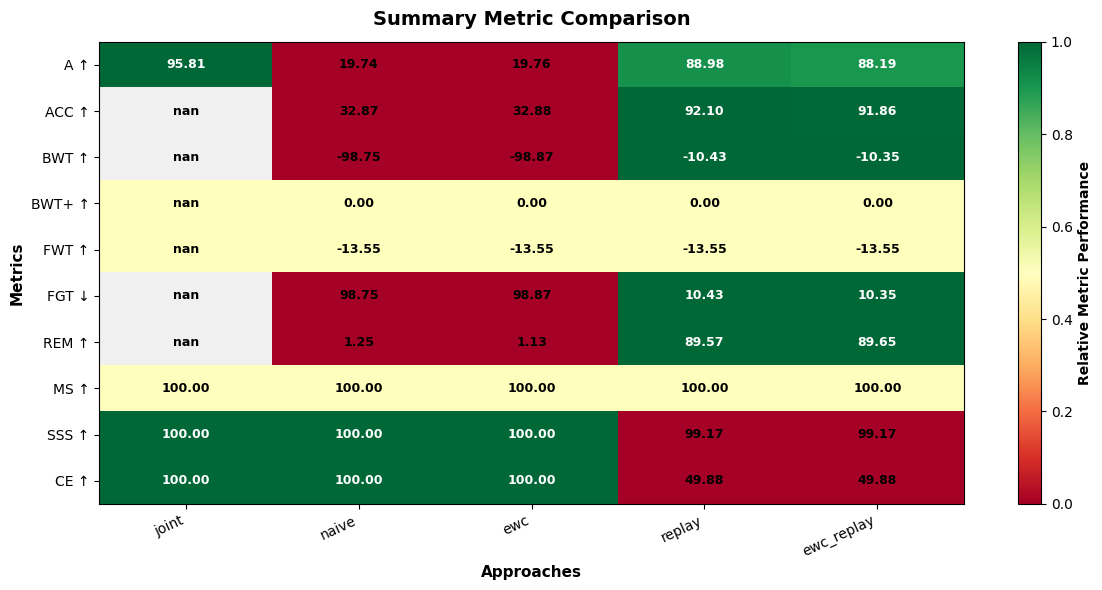

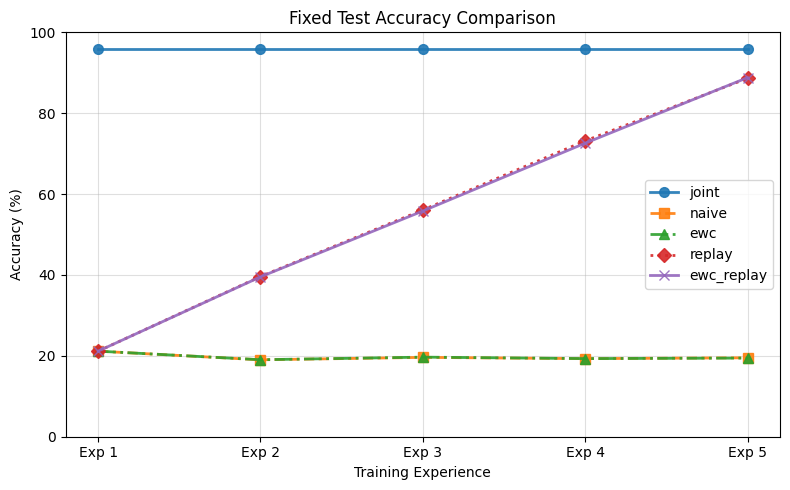

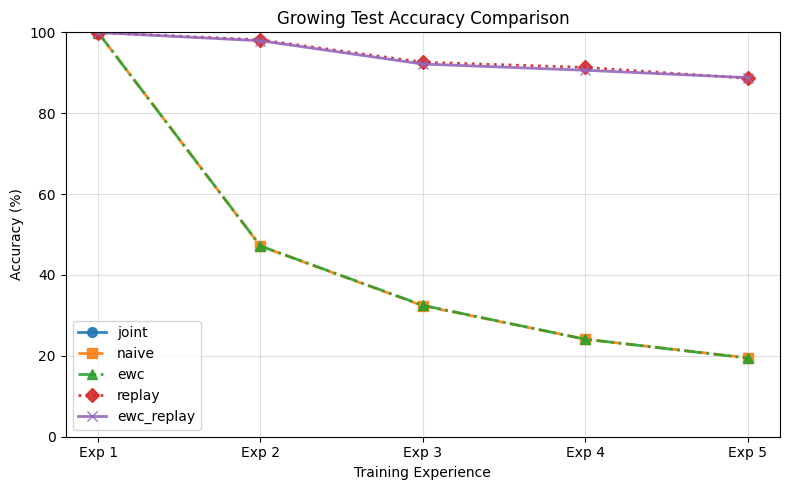

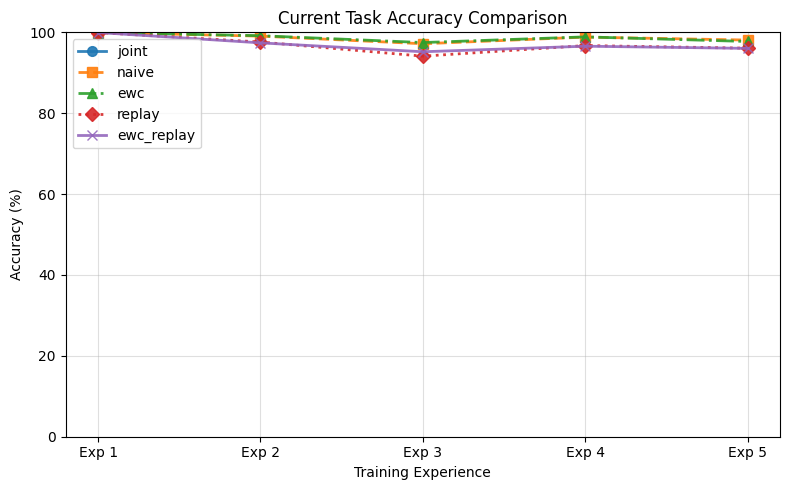

In [14]:
plot_metric_comparison(all_results)
plot_fixed_comparison(all_results)
plot_growing_comparison(all_results)
plot_task_comparison(all_results)

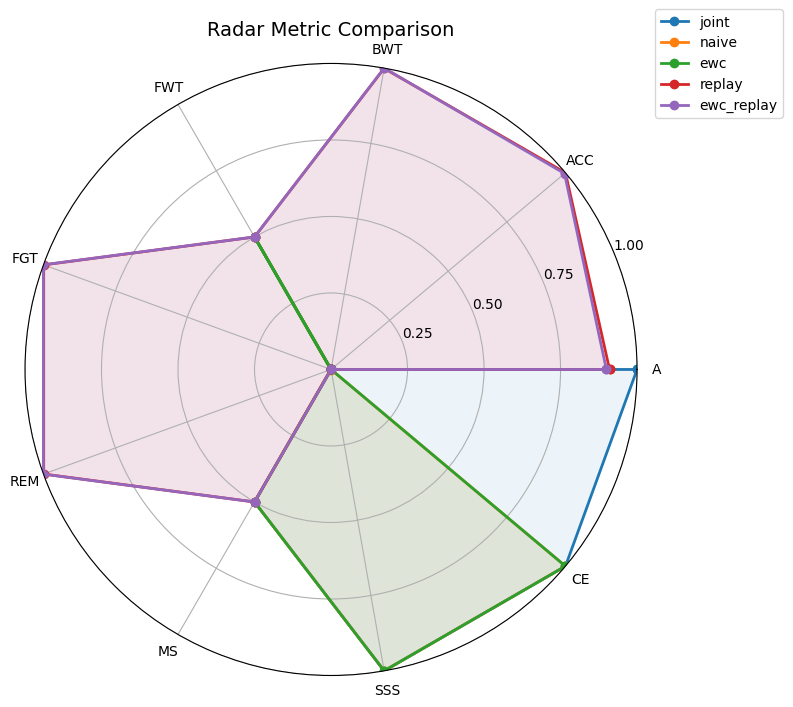

In [15]:
plot_radar_metrics(
    all_results,
    metric_names={
        "A Metric": "A",
        "ACC Metric": "ACC",
        "BWT (Backward Transfer)": "BWT",
        "FWT (Forward Transfer)": "FWT",
        "Forgetting": "FGT",
        "REM (Remembering)": "REM",
        "MS (Memory Score)": "MS",
        "SSS (Sample Storage Score)": "SSS",
        "CE (Compute Efficiency)": "CE",
    },
)